# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it.

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16).
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [1]:
import random

class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def value(self):
        if self.rank in ["J", "Q", "K"]:
            return 10
        elif self.rank == "A":
            return 11
        else:
            return int(self.rank)

    def __str__(self):
        return self.rank + " of " + self.suit

In [2]:
class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.shuffle()

    def shuffle(self):
        self.cards = []
        self.needs_shuffle = False

        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["2", "3", "4", "5", "6", "7", "8",
                 "9", "10", "J", "Q", "K", "A"]

        for i in range(self.num_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(rank, suit))

        random.shuffle(self.cards)

        position = random.randint(52, len(self.cards) - 52)
        self.cards.insert(position, "plastic")

    def draw(self):
        card = self.cards.pop()

        if card == "plastic":
            self.needs_shuffle = True
            card = self.cards.pop()

        return card

In [3]:
deck = Deck()

print("Cards including plastic card:", len(deck.cards))

for i in range(5):
    card = deck.draw()
    print(card, "- value:", card.value())

Cards including plastic card: 313
K of Clubs - value: 10
9 of Diamonds - value: 9
K of Spades - value: 10
2 of Spades - value: 2
3 of Spades - value: 3


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook.

My game will use Card, Deck, Hand, Player, and Game classes. DealerPlayer, HumanPlayer, and CountingPlayer will inherit from Player and use different ways to decide whether to hit or stay. The Game class will control dealing, turns, bets, and payouts.

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [4]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def total(self):
        pass

    def is_blackjack(self):
        pass


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def decide(self):
        pass

    def observe(self, card):
        pass


class DealerPlayer(Player):
    def decide(self):
        pass


class HumanPlayer(Player):
    def decide(self):
        pass


class Game:
    def __init__(self, players, num_decks=6, verbose=True):
        self.deck = Deck(num_decks)
        self.players = players
        self.dealer = DealerPlayer("Dealer")
        self.verbose = verbose

    def play_round(self):
        pass

    def play(self, rounds):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [5]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def total(self):
        total = 0
        aces = 0

        for card in self.cards:
            total += card.value()

            if card.rank == "A":
                aces += 1

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_blackjack(self):
        return len(self.cards) == 2 and self.total() == 21

In [6]:
class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def decide(self):
        return "stay"

    def observe(self, card):
        pass


class DealerPlayer(Player):
    def decide(self):
        if self.hand.total() < 17:
            return "hit"
        else:
            return "stay"


class HumanPlayer(Player):
    def decide(self):
        print("Your hand:")
        for card in self.hand.cards:
            print(card)

        print("Total:", self.hand.total())

        choice = input("Hit or stay? ").strip().lower()

        while choice not in ["hit", "stay"]:
            choice = input("Enter hit or stay: ").strip().lower()

        return choice

In [7]:
class Game:
    def __init__(self, players, num_decks=6, verbose=True):
        self.deck = Deck(num_decks)
        self.players = players
        self.dealer = DealerPlayer("Dealer")
        self.verbose = verbose

    def show_card(self, card):
        for player in self.players:
            player.observe(card)

    def deal_card(self, player, visible=True):
        card = self.deck.draw()
        player.hand.add_card(card)

        if visible:
            self.show_card(card)

        return card

    def play_round(self):
        if self.deck.needs_shuffle or len(self.deck.cards) < 75:
            self.deck.shuffle()

            for player in self.players:
                if hasattr(player, "count"):
                    player.count = 0

        active = []

        for player in self.players:
            player.hand = Hand()
            player.bet = 0

            if player.chips >= 10:
                player.bet = 10
                player.chips -= player.bet
                active.append(player)

        if len(active) == 0:
            return

        self.dealer.hand = Hand()

        for player in active:
            self.deal_card(player)

        up_card = self.deal_card(self.dealer)

        for player in active:
            self.deal_card(player)

        hidden_card = self.deal_card(self.dealer, visible=False)

        if self.verbose:
            print("\nDealer shows:", up_card)

        if not self.dealer.hand.is_blackjack():
            for player in active:
                while player.hand.total() < 21:
                    if player.decide() == "stay":
                        break

                    card = self.deal_card(player)

                    if self.verbose:
                        print(player.name, "draws", card)

        self.show_card(hidden_card)

        if self.verbose:
            print("Dealer reveals:", hidden_card)

        while self.dealer.decide() == "hit":
            card = self.deal_card(self.dealer)

            if self.verbose:
                print("Dealer draws", card)

        dealer_total = self.dealer.hand.total()

        if self.verbose:
            print("Dealer total:", dealer_total)

        for player in active:
            total = player.hand.total()

            if total > 21:
                result = "Bust"

            elif self.dealer.hand.is_blackjack():
                if player.hand.is_blackjack():
                    player.chips += player.bet
                    result = "Tie"
                else:
                    result = "Loss"

            elif player.hand.is_blackjack():
                player.chips += player.bet * 2.5
                result = "Blackjack"

            elif dealer_total > 21 or total > dealer_total:
                player.chips += player.bet * 2
                result = "Win"

            elif total == dealer_total:
                player.chips += player.bet
                result = "Tie"

            else:
                result = "Loss"

            if self.verbose:
                print(player.name, "- total:", total,
                      "-", result, "- chips:", player.chips)

    def play(self, rounds):
        rounds_played = 0

        for i in range(rounds):
            if not any(player.chips >= 10 for player in self.players):
                break

            if self.verbose:
                print("\nRound", i + 1)

            self.play_round()
            rounds_played += 1

        return rounds_played

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [9]:
players = [
    DealerPlayer("Player 1"),
    DealerPlayer("Player 2"),
    DealerPlayer("Player 3")
]

game = Game(players)
game.play(5)

print("\nFinal chips:")
for player in players:
    print(player.name, ":", player.chips)


Round 1

Dealer shows: 2 of Clubs
Player 2 draws 3 of Clubs
Player 2 draws 8 of Diamonds
Dealer reveals: Q of Diamonds
Dealer draws 4 of Spades
Dealer draws K of Spades
Dealer total: 26
Player 1 - total: 20 - Win - chips: 110
Player 2 - total: 23 - Bust - chips: 90
Player 3 - total: 18 - Win - chips: 110

Round 2

Dealer shows: 5 of Diamonds
Player 3 draws 5 of Spades
Player 3 draws 10 of Diamonds
Dealer reveals: 6 of Hearts
Dealer draws A of Clubs
Dealer draws 10 of Hearts
Dealer total: 22
Player 1 - total: 17 - Win - chips: 120
Player 2 - total: 19 - Win - chips: 100
Player 3 - total: 20 - Win - chips: 120

Round 3

Dealer shows: K of Clubs
Player 1 draws Q of Diamonds
Player 3 draws 3 of Hearts
Dealer reveals: 2 of Hearts
Dealer draws 7 of Hearts
Dealer total: 19
Player 1 - total: 25 - Bust - chips: 110
Player 2 - total: 17 - Loss - chips: 90
Player 3 - total: 19 - Tie - chips: 120

Round 4

Dealer shows: Q of Hearts
Player 1 draws 6 of Spades
Player 1 draws Q of Hearts
Player 2 dr

6. Implement a new player with the following strategy:

    * Assign each card a value:
        * Cards 2 to 6 are +1
        * Cards 7 to 9 are 0
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [10]:
class CountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.count = 0
        self.threshold = threshold

    def observe(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            self.count += 1

        elif card.rank in ["10", "J", "Q", "K", "A"]:
            self.count -= 1

    def decide(self):
        if self.count < self.threshold:
            return "hit"
        else:
            return "stay"

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [11]:
counter = CountingPlayer("Counter", chips=100, threshold=0)

players = [
    counter,
    DealerPlayer("Player 2", chips=100),
    DealerPlayer("Player 3", chips=100),
    DealerPlayer("Player 4", chips=100)
]

game = Game(players, verbose=False)
rounds_played = 0

for i in range(50):
    if counter.chips < 10:
        break

    game.play_round()
    rounds_played += 1

winnings = counter.chips - 100

print("Rounds played:", rounds_played)
print("Starting chips:", 100)
print("Final chips:", counter.chips)
print("Net winnings:", winnings)

Rounds played: 10
Starting chips: 100
Final chips: 0
Net winnings: -100


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Average net winnings per game: -93.65
Average winnings per round: -3.592251630226314
Standard deviation of net winnings: 15.073138191813106
Probability of net winning: 0.0
Probability of net losing: 1.0
Probability of breaking even: 0.0


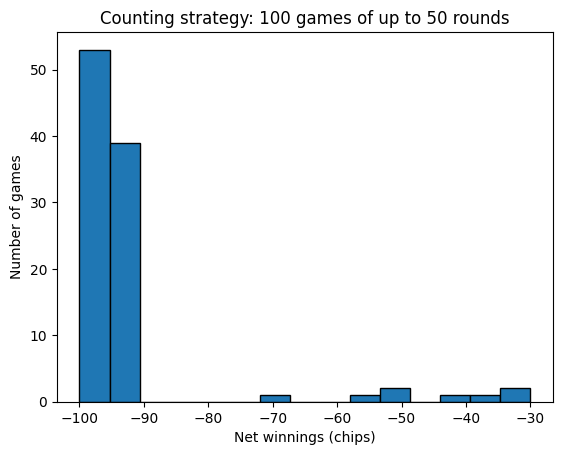

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def run_test(threshold):
    counter = CountingPlayer("Counter", chips=100,
                             threshold=threshold)

    players = [
        counter,
        DealerPlayer("Player 2", chips=100),
        DealerPlayer("Player 3", chips=100),
        DealerPlayer("Player 4", chips=100)
    ]

    game = Game(players, verbose=False)
    rounds_played = 0

    for i in range(50):
        if counter.chips < 10:
            break

        game.play_round()
        rounds_played += 1

    return counter.chips, rounds_played


random.seed(42)

ending_chips = []
round_counts = []

for i in range(100):
    chips, rounds = run_test(threshold=0)
    ending_chips.append(chips)
    round_counts.append(rounds)

net_winnings = np.array(ending_chips) - 100

average_per_round = np.sum(net_winnings) / np.sum(round_counts)

print("Average net winnings per game:", np.mean(net_winnings))
print("Average winnings per round:", average_per_round)
print("Standard deviation of net winnings:",
      np.std(net_winnings, ddof=1))
print("Probability of net winning:", np.mean(net_winnings > 0))
print("Probability of net losing:", np.mean(net_winnings < 0))
print("Probability of breaking even:", np.mean(net_winnings == 0))

plt.hist(net_winnings, bins=15, edgecolor="black")
plt.xlabel("Net winnings (chips)")
plt.ylabel("Number of games")
plt.title("Counting strategy: 100 games of up to 50 rounds")
plt.show()

With a threshold of 0, the counting player lost an average of 93.65 chips per game, or about 3.59 chips per round. The standard deviation of net winnings was about 15.07 chips. All 100 simulated games ended with a net loss, so the estimated probability of losing was 100% in this test.

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [13]:
thresholds = [-10, -5, 0, 5, 10]
results = []

for threshold in thresholds:
    random.seed(42)

    profits = []
    rounds_list = []

    for i in range(100):
        chips, rounds = run_test(threshold)
        profits.append(chips - 100)
        rounds_list.append(rounds)

    average_game = np.mean(profits)
    average_round = np.sum(profits) / np.sum(rounds_list)
    standard_dev = np.std(profits, ddof=1)
    win_probability = np.mean(np.array(profits) > 0)
    loss_probability = np.mean(np.array(profits) < 0)

    results.append((threshold, average_round))

    print("\nThreshold:", threshold)
    print("Average net winnings per game:", round(average_game, 2))
    print("Average winnings per round:", round(average_round, 2))
    print("Standard deviation:", round(standard_dev, 2))
    print("Probability of net winning:", win_probability)
    print("Probability of net losing:", loss_probability)

best = max(results, key=lambda result: result[1])

print("\nBest tested threshold:", best[0])
print("Average winnings per round:", round(best[1], 2))


Threshold: -10
Average net winnings per game: -73.35
Average winnings per round: -1.93
Standard deviation: 38.99
Probability of net winning: 0.07
Probability of net losing: 0.93

Threshold: -5
Average net winnings per game: -80.95
Average winnings per round: -2.37
Standard deviation: 35.49
Probability of net winning: 0.05
Probability of net losing: 0.95

Threshold: 0
Average net winnings per game: -93.65
Average winnings per round: -3.59
Standard deviation: 15.07
Probability of net winning: 0.0
Probability of net losing: 1.0

Threshold: 5
Average net winnings per game: -97.8
Average winnings per round: -4.78
Standard deviation: 3.71
Probability of net winning: 0.0
Probability of net losing: 1.0

Threshold: 10
Average net winnings per game: -98.15
Average winnings per round: -5.89
Standard deviation: 2.43
Probability of net winning: 0.0
Probability of net losing: 1.0

Best tested threshold: -10
Average winnings per round: -1.93


I tested thresholds of −10, −5, 0, 5, and 10. The best threshold tested was −10, which lost about 1.93 chips per round and finished with a profit in 7% of games. Higher thresholds performed worse in these simulations. This does not prove −10 is the overall optimal threshold because I only tested five values.

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings.

In [14]:
class SimplePlayer(Player):
    def decide(self):
        if self.hand.total() < 17:
            return "hit"
        else:
            return "stay"


def test_simple():
    player = SimplePlayer("Simple player", chips=100)

    players = [
        player,
        DealerPlayer("Player 2", chips=100),
        DealerPlayer("Player 3", chips=100),
        DealerPlayer("Player 4", chips=100)
    ]

    game = Game(players, verbose=False)
    rounds_played = 0

    for i in range(50):
        if player.chips < 10:
            break

        game.play_round()
        rounds_played += 1

    return player.chips, rounds_played


for strategy in ["Counting", "Simple"]:
    random.seed(123)
    profits = []
    round_counts = []

    for i in range(100):
        if strategy == "Counting":
            chips, rounds = run_test(-10)
        else:
            chips, rounds = test_simple()

        profits.append(chips - 100)
        round_counts.append(rounds)

    print("\nStrategy:", strategy)
    print("Average net winnings per game:",
          round(np.mean(profits), 2))
    print("Average winnings per round:",
          round(np.sum(profits) / np.sum(round_counts), 2))
    print("Standard deviation:",
          round(np.std(profits, ddof=1), 2))
    print("Probability of net winning:",
          np.mean(np.array(profits) > 0))


Strategy: Counting
Average net winnings per game: -67.05
Average winnings per round: -1.84
Standard deviation: 45.3
Probability of net winning: 0.12

Strategy: Simple
Average net winnings per game: -24.2
Average winnings per round: -0.53
Standard deviation: 64.26
Probability of net winning: 0.31


My new strategy hits when the hand total is below 17 and stays at 17 or higher. In 100 simulated games, it lost an average of 24.20 chips per game, compared with 67.05 chips for the counting strategy using a threshold of −10. It also finished with a profit in 31% of games, compared with 12% for the counting strategy. The simple strategy performed better in this test, but neither strategy made money on average.